<a href="https://colab.research.google.com/github/naveenkumardevillers-stack/Boundary_detection_FTW/blob/main/FTW_Jupyter_Notebook_Complete/FTW_Field_Boundary_Detection_V1.2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import math
import subprocess
from pathlib import Path
import geopandas as gpd
import pandas as pd
import rasterio
import matplotlib.pyplot as plt
import numpy as np
import rasterio
from rasterio.windows import from_bounds
from rasterio.warp import transform_bounds
from pystac_client import Client
import planetary_computer as pc
from shapely.geometry import Point
from rasterio.transform import array_bounds

from rasterio.vrt import WarpedVRT
from rasterio.enums import Resampling
from rasterio.features import geometry_mask

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)

In [2]:


from pathlib import Path

PROJECT_DIR = Path("/content/Boundary_detection_FTW")

OUTPUT_DIR = PROJECT_DIR / "gps_ftw_output"
SATELLITE_DIR = PROJECT_DIR / "preprocessed_satellite"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SATELLITE_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Project exists:", PROJECT_DIR.exists())
print("FTW output directory:", OUTPUT_DIR)
print("Satellite directory:", SATELLITE_DIR)

Project directory: /content/Boundary_detection_FTW
Project exists: True
FTW output directory: /content/Boundary_detection_FTW/gps_ftw_output
Satellite directory: /content/Boundary_detection_FTW/preprocessed_satellite


In [3]:
import sys
import shutil
import importlib.util

print("Python executable:", sys.executable)
print("FTW executable:", shutil.which("ftw"))
print("FTW package:", importlib.util.find_spec("ftw_tools"))

Python executable: /usr/bin/python3
FTW executable: /usr/local/bin/ftw
FTW package: ModuleSpec(name='ftw_tools', loader=<_frozen_importlib_external.SourceFileLoader object at 0x7e67619bdf70>, origin='/content/FTW_Project/ftw_tools/__init__.py', submodule_search_locations=['/content/FTW_Project/ftw_tools'])


In [4]:
%cd /content/Boundary_detection_FTW

/content/Boundary_detection_FTW


In [5]:
from pathlib import Path

PROJECT_DIR = Path("/content/Boundary_detection_FTW")

print("Repository contents:")
for item in PROJECT_DIR.iterdir():
    print(item.name)

print("\nSearching for pyproject.toml:")
for file in PROJECT_DIR.rglob("pyproject.toml"):
    print(file)

Repository contents:
gps_ftw_output
preprocessed_satellite
satellite_preprocessing

Searching for pyproject.toml:


In [6]:
from pathlib import Path
import subprocess

REPO_DIR = Path("/content/Boundary_detection_FTW")

result = subprocess.run(
    ["ftw", "inference", "all", "--help"],
    cwd=str(REPO_DIR),
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print("Error:")
    print(result.stderr)

Usage: ftw inference all [OPTIONS]

  Run all inference commands from crop calendar scene selection,then download,
  inference and polygonize.

Options:
  -o, --out PATH                  Directory to save downloaded inference
                                  imagery, and inference output to  [required]
  -m, --model MODEL_OR_CHECKPOINT
                                  Short model name from the registry OR path
                                  to a checkpoint file (.ckpt).  [required]
  --year INTEGER RANGE            Year to run model inference over
                                  [2015<=x<=2026; required]
  --bbox TEXT                     Bounding box to use for the download in the
                                  format 'minx,miny,maxx,maxy'
  -ccx, --cloud_cover_max INTEGER RANGE
                                  Maximum percentage of cloud cover allowed in
                                  the Sentinel-2 scene  [default: 20;
                                  0<=x<=100]
  -b, 

In [7]:
# !pip install planetary-computer pystac-client rasterio numpy matplotlib pandas

# Existing baseline GPS coordinates
latitude = 42.099946
longitude = -93.681996

# Create approximately 2 km bounding box
# 1 degree latitude ≈ 111.32 km
lat_offset = 2000 / 111320

# Longitude distance varies with latitude
lon_offset = 2000 / (
    111320 * np.cos(np.radians(latitude))
)

bbox = [
    longitude - lon_offset,  # Minimum longitude
    latitude - lat_offset,   # Minimum latitude
    longitude + lon_offset,  # Maximum longitude
    latitude + lat_offset    # Maximum latitude
]

print("Your bounding box:", bbox)

Your bounding box: [np.float64(-93.70621000699016), 42.081979776500184, np.float64(-93.65778199300983), 42.11791222349982]


In [10]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
import planetary_computer as pc

from pystac_client import Client
from rasterio.warp import transform_bounds, reproject, Resampling
from rasterio.windows import from_bounds, Window
from rasterio.vrt import WarpedVRT

# Reuse your existing bbox if already defined in the notebook.
# Format: [min_longitude, min_latitude, max_longitude, max_latitude]
if "bbox" not in globals():
    raise ValueError("Please define your existing bbox before running this cell.")

# Use the same period as your baseline for a fair comparison.
DATE_RANGE = "2025-04-01/2025-10-31"

MAX_SCENE_CLOUD = 40
TOP_SCENES_TO_INSPECT = 15

OUTPUT_DIR = Path(
    r"/content/Boundary_detection_FTW/preprocessed_satellite"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Bounding box:", bbox)
print("Date range:", DATE_RANGE)
print("Output folder:", OUTPUT_DIR)

Bounding box: [np.float64(-93.70621000699016), 42.081979776500184, np.float64(-93.65778199300983), 42.11791222349982]
Date range: 2025-04-01/2025-10-31
Output folder: /content/Boundary_detection_FTW/preprocessed_satellite


In [11]:
catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=pc.sign_inplace
)

search = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=bbox,
    datetime=DATE_RANGE,
    query={
        "eo:cloud_cover": {"lt": MAX_SCENE_CLOUD}
    },
    max_items=100
)

items = list(search.items())

print("Total candidate scenes:", len(items))

if not items:
    raise RuntimeError(
        "No Sentinel-2 scenes found. Try increasing MAX_SCENE_CLOUD "
        "or expanding DATE_RANGE."
    )

# Sort using scene cloud metadata, then acquisition date.
items.sort(
    key=lambda x: (
        x.properties.get("eo:cloud_cover", 100),
        -x.datetime.timestamp()
    )
)

for item in items[:10]:
    print(
        item.id,
        "| Date:", item.datetime.date(),
        "| Scene cloud:", item.properties.get("eo:cloud_cover")
    )

Total candidate scenes: 45
S2B_MSIL2A_20250927T165959_R069_T15TVG_20250927T224244 | Date: 2025-09-27 | Scene cloud: 0.000952
S2B_MSIL2A_20251010T171139_R112_T15TVG_20251010T220405 | Date: 2025-10-10 | Scene cloud: 0.001145
S2C_MSIL2A_20250508T170911_R112_T15TVG_20250508T225059 | Date: 2025-05-08 | Scene cloud: 0.003658
S2B_MSIL2A_20250619T165849_R069_T15TVG_20250619T210543 | Date: 2025-06-19 | Scene cloud: 0.007024
S2C_MSIL2A_20250408T170911_R112_T15TVG_20250408T223604 | Date: 2025-04-08 | Scene cloud: 0.026546
S2B_MSIL2A_20250510T165849_R069_T15TVG_20250510T205750 | Date: 2025-05-10 | Scene cloud: 0.052465
S2C_MSIL2A_20251002T170141_R069_T15TVG_20251002T222514 | Date: 2025-10-02 | Scene cloud: 0.065839
S2C_MSIL2A_20250714T165921_R069_T15TVG_20250714T222410 | Date: 2025-07-14 | Scene cloud: 0.132846
S2B_MSIL2A_20250622T170849_R112_T15TVG_20250622T204748 | Date: 2025-06-22 | Scene cloud: 0.206303
S2C_MSIL2A_20250826T170911_R112_T15TVG_20250826T221113 | Date: 2025-08-26 | Scene cloud: 0.

In [12]:
def get_local_scl_quality(item, bbox):
    signed_item = pc.sign(item)

    if "SCL" not in signed_item.assets:
        return None

    scl_href = signed_item.assets["SCL"].href

    with rasterio.open(scl_href) as src:

        projected_bounds = transform_bounds(
            "EPSG:4326",
            src.crs,
            *bbox
        )

        window = from_bounds(
            *projected_bounds,
            transform=src.transform
        )

        window = window.intersection(
            Window(0, 0, src.width, src.height)
        )

        if window.width <= 0 or window.height <= 0:
            return None

        scl = src.read(
            1,
            window=window,
            masked=True
        )

    scl_data = scl.compressed()

    if len(scl_data) == 0:
        return None

    # Cloud, shadow, cirrus, dark-area, unclassified,
    # no-data and defective pixels.
    invalid_classes = [0, 1, 2, 3, 7, 8, 9, 10, 11]

    invalid_pixels = np.isin(
        scl_data,
        invalid_classes
    )

    invalid_percent = (
        invalid_pixels.sum() / len(scl_data)
    ) * 100

    cloud_shadow_classes = [3, 8, 9, 10]

    cloud_shadow_pixels = np.isin(
        scl_data,
        cloud_shadow_classes
    )

    cloud_shadow_percent = (
        cloud_shadow_pixels.sum() / len(scl_data)
    ) * 100

    return {
        "local_invalid_percent": invalid_percent,
        "local_cloud_shadow_percent": cloud_shadow_percent,
        "local_valid_pixels": len(scl_data) - invalid_pixels.sum()
    }

In [13]:
scene_results = []

for item in items[:TOP_SCENES_TO_INSPECT]:

    quality = get_local_scl_quality(item, bbox)

    if quality is None:
        continue

    scene_results.append({
        "scene_id": item.id,
        "date": item.datetime.date(),
        "scene_cloud_percent": item.properties.get(
            "eo:cloud_cover", np.nan
        ),
        **quality,
        "item": item
    })

if not scene_results:
    raise RuntimeError(
        "Could not evaluate SCL quality for the candidate scenes."
    )

scene_df = pd.DataFrame(scene_results)

scene_df = scene_df.sort_values(
    by=[
        "local_invalid_percent",
        "scene_cloud_percent",
        "date"
    ],
    ascending=[True, True, False]
).reset_index(drop=True)

display(
    scene_df[
        [
            "scene_id",
            "date",
            "scene_cloud_percent",
            "local_invalid_percent",
            "local_cloud_shadow_percent"
        ]
    ]
)

,scene_id,date,scene_cloud_percent,local_invalid_percent,local_cloud_shadow_percent
0,S2B_MSIL2A_20250927T165959_R069_T15TVG_20250927T224244,2025-09-27,0.000952,0.000000,0.000000
1,S2B_MSIL2A_20251010T171139_R112_T15TVG_20251010T220405,2025-10-10,0.001145,0.000000,0.000000
2,S2C_MSIL2A_20251002T170141_R069_T15TVG_20251002T222514,2025-10-02,0.065839,0.000000,0.000000
3,S2B_MSIL2A_20250622T170849_R112_T15TVG_20250622T204748,2025-06-22,0.206303,0.022166,0.000000
4,S2C_MSIL2A_20250415T165911_R069_T15TVG_20250415T232314,2025-04-15,0.802021,0.115758,0.019703
5,S2C_MSIL2A_20250813T165911_R069_T15TVG_20250813T220414,2025-08-13,0.610449,0.130535,0.000000
6,S2B_MSIL2A_20250619T165849_R069_T15TVG_20250619T210543,2025-06-19,0.007024,0.290626,0.000000
7,S2B_MSIL2A_20250510T165849_R069_T15TVG_20250510T205750,2025-05-10,0.052465,0.298015,0.000000
8,S2B_MSIL2A_20250513T170849_R112_T15TVG_20250513T211256,2025-05-13,3.229664,0.352199,0.000000
9,S2C_MSIL2A_20250714T165921_R069_T15TVG_20250714T222410,2025-07-14,0.132846,0.366977,0.004926


In [14]:
selected_item = scene_df.loc[0, "item"]
selected_item = pc.sign(selected_item)

print("Selected scene:", selected_item.id)
print("Acquisition date:", selected_item.datetime)
print(
    "Scene cloud cover:",
    selected_item.properties.get("eo:cloud_cover")
)
print(
    "Local invalid pixels (%):",
    round(scene_df.loc[0, "local_invalid_percent"], 2)
)

Selected scene: S2B_MSIL2A_20250927T165959_R069_T15TVG_20250927T224244
Acquisition date: 2025-09-27 16:59:59.024000+00:00
Scene cloud cover: 0.000952
Local invalid pixels (%): 0.0


In [15]:
assets = selected_item.assets

required_assets = ["B02", "B03", "B04", "B08", "SCL"]

missing = [band for band in required_assets if band not in assets]

if missing:
    raise RuntimeError(f"Missing Sentinel-2 assets: {missing}")

# B04 defines our reference 10-metre grid.
with rasterio.open(assets["B04"].href) as red_src:

    target_crs = red_src.crs
    target_transform = red_src.transform
    target_width = red_src.width
    target_height = red_src.height

    projected_bounds = transform_bounds(
        "EPSG:4326",
        target_crs,
        *bbox
    )

    window = from_bounds(
        *projected_bounds,
        transform=target_transform
    )

    window = window.intersection(
        Window(0, 0, target_width, target_height)
    )

    window = window.round_offsets().round_lengths()

    if window.width <= 0 or window.height <= 0:
        raise RuntimeError("Bounding box does not overlap the selected scene.")

    window_transform = red_src.window_transform(window)

    height = int(window.height)
    width = int(window.width)

    red = red_src.read(1, window=window)

print("Output dimensions:", width, "x", height)
print("CRS:", target_crs)

Output dimensions: 404 x 402
CRS: EPSG:32615


In [16]:
def read_band_on_reference(
    asset,
    target_crs,
    target_transform,
    width,
    height,
    window
):
    with rasterio.open(asset.href) as src:

        with WarpedVRT(
            src,
            crs=target_crs,
            transform=target_transform,
            width=src.width if src.crs == target_crs
                    and src.transform == target_transform
                    else None,
            height=src.height if src.crs == target_crs
                    and src.transform == target_transform
                    else None,
            resampling=Resampling.bilinear
        ) as vrt:

            # This function is not used for the reference band;
            # use the dedicated reference grid below.
            pass

In [17]:
def read_aligned_band(asset, reference_grid, window, resampling):
    crs, transform, full_width, full_height = reference_grid

    with rasterio.open(asset.href) as src:

        with WarpedVRT(
            src,
            crs=crs,
            transform=transform,
            width=full_width,
            height=full_height,
            resampling=resampling
        ) as vrt:

            return vrt.read(1, window=window)


reference_grid = (
    target_crs,
    target_transform,
    target_width,
    target_height
)

blue = read_aligned_band(
    assets["B02"], reference_grid, window, Resampling.bilinear
)

green = read_aligned_band(
    assets["B03"], reference_grid, window, Resampling.bilinear
)

nir = read_aligned_band(
    assets["B08"], reference_grid, window, Resampling.bilinear
)

scl = read_aligned_band(
    assets["SCL"], reference_grid, window, Resampling.nearest
)

print("Band shapes:", {
    "B02": blue.shape,
    "B03": green.shape,
    "B04": red.shape,
    "B08": nir.shape,
    "SCL": scl.shape
})

Band shapes: {'B02': (402, 404), 'B03': (402, 404), 'B04': (402, 404), 'B08': (402, 404), 'SCL': (402, 404)}


In [18]:
invalid_classes = [0, 1, 2, 3, 7, 8, 9, 10, 11]

cloud_mask = np.isin(scl, invalid_classes)

# Also exclude zero-valued reflectance pixels.
nodata_mask = (
    (blue == 0) |
    (green == 0) |
    (red == 0) |
    (nir == 0)
)

final_mask = cloud_mask | nodata_mask

print("Total pixels:", final_mask.size)

print(
    "Invalid/cloud pixels (%):",
    round(final_mask.mean() * 100, 2)
)

print(
    "Usable pixels (%):",
    round((~final_mask).mean() * 100, 2)
)

Total pixels: 162408
Invalid/cloud pixels (%): 0.0
Usable pixels (%): 100.0


In [19]:
# red_float = red.astype("float32")
# nir_float = nir.astype("float32")

# denominator = nir_float + red_float

# ndvi = np.full(
#     red.shape,
#     np.nan,
#     dtype="float32"
# )

# valid = (~final_mask) & (denominator != 0)

# ndvi[valid] = (
#     nir_float[valid] - red_float[valid]
# ) / denominator[valid]

# print("Valid NDVI pixels:", np.isfinite(ndvi).sum())
# print("Mean NDVI:", np.nanmean(ndvi))
# print("Median NDVI:", np.nanmedian(ndvi))
# print("Minimum NDVI:", np.nanmin(ndvi))
# print("Maximum NDVI:", np.nanmax(ndvi))

In [20]:
print(f" {'*'*25} Sentinel-2 Image selection completed {'*'*25}")

 ************************* Sentinel-2 Image selection completed *************************


### Sentinel-2 Image Preprocessing

In [21]:
import os
import numpy as np
import rasterio
import planetary_computer
import pystac_client
import matplotlib.pyplot as plt
import pandas as pd

from pathlib import Path
from rasterio.warp import reproject, Resampling
from scipy.ndimage import binary_dilation

print("All libraries imported successfully.")

All libraries imported successfully.


In [22]:
#Connect to Sentinel-2 imagery

catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace
)

print("Connected to Planetary Computer.")

Connected to Planetary Computer.


In [28]:
SCENE_IDS = [
    "S2B_MSIL2A_20250927T165959_R069_T15TVG_20250927T224244",
    "S2B_MSIL2A_20251010T171139_R112_T15TVG_20251010T220405"
    # "S2C_MSIL2A_20251002T170141_R069_T15TVG_20251002T222514"
]

items = list(
    catalog.search(
        collections=["sentinel-2-l2a"],
        ids=SCENE_IDS
    ).items()
)

print("Scenes retrieved:", len(items))

for item in items:
    print(item.id, item.datetime)

Scenes retrieved: 2
S2B_MSIL2A_20251010T171139_R112_T15TVG_20251010T220405 2025-10-10 17:11:39.024000+00:00
S2B_MSIL2A_20250927T165959_R069_T15TVG_20250927T224244 2025-09-27 16:59:59.024000+00:00


In [29]:
#preprocessing output order

PROJECT_DIR = Path("/content/Boundary_detection_FTW")

OUTPUT_DIR = PROJECT_DIR / "satellite_preprocessing"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Output folder:", OUTPUT_DIR)

Output folder: /content/Boundary_detection_FTW/satellite_preprocessing


In [30]:
#inspecting available satellite bands

for item in items:

    print("\nScene:", item.id)

    for band in ["B02", "B03", "B04", "B08", "SCL"]:
        if band in item.assets:
            print(band, "Available")
        else:
            print(band, "Missing")


Scene: S2B_MSIL2A_20251010T171139_R112_T15TVG_20251010T220405
B02 Available
B03 Available
B04 Available
B08 Available
SCL Available

Scene: S2B_MSIL2A_20250927T165959_R069_T15TVG_20250927T224244
B02 Available
B03 Available
B04 Available
B08 Available
SCL Available


In [31]:

from rasterio.windows import from_bounds, Window
from rasterio.warp import reproject, Resampling, transform_bounds
from scipy.ndimage import binary_dilation
import rasterio
import numpy as np

# Iowa study-area bounding box: min longitude, min latitude,
# max longitude, max latitude
BBOX = (
    -93.70621000699016,
    42.081979776500184,
    -93.65778199300983,
    42.11791222349982
)


def read_band_on_reference(
    item,
    band_name,
    reference_crs,
    reference_transform,
    reference_width,
    reference_height
):

    asset = item.assets[band_name]

    with rasterio.open(asset.href) as src:

        destination = np.zeros(
            (reference_height, reference_width),
            dtype=np.uint16
        )

        reproject(
            source=rasterio.band(src, 1),
            destination=destination,
            src_transform=src.transform,
            src_crs=src.crs,
            dst_transform=reference_transform,
            dst_crs=reference_crs,
            resampling=Resampling.nearest,
            src_nodata=src.nodata,
            dst_nodata=0
        )

    return destination


def preprocess_scene(item):

    print("\nProcessing:", item.id)

    b02_href = item.assets["B02"].href

    # Read only the study-area portion of the reference image
    with rasterio.open(b02_href) as reference:

        projected_bounds = transform_bounds(
            "EPSG:4326",
            reference.crs,
            *BBOX,
            densify_pts=21
        )

        window = from_bounds(
            *projected_bounds,
            transform=reference.transform
        )

        window = window.round_offsets().round_lengths()

        window = window.intersection(
            Window(0, 0, reference.width, reference.height)
        )

        reference_transform = reference.window_transform(window)

        reference_width = int(window.width)
        reference_height = int(window.height)

        reference_crs = reference.crs

        profile = reference.profile.copy()

    print(
        "Cropped image dimensions:",
        reference_width,
        "x",
        reference_height
    )

    bands = {}

    # Align required bands to the cropped 10 m grid
    for band in ["B02", "B03", "B04", "B08", "SCL"]:

        bands[band] = read_band_on_reference(
            item,
            band,
            reference_crs,
            reference_transform,
            reference_width,
            reference_height
        )

    # Identify invalid pixels
    invalid_classes = [0, 1, 3, 7, 8, 9, 10, 11]

    invalid_mask = np.isin(
        bands["SCL"],
        invalid_classes
    )

    invalid_mask |= (
        (bands["B02"] == 0) |
        (bands["B03"] == 0) |
        (bands["B04"] == 0) |
        (bands["B08"] == 0)
    )

    # Expand cloud and shadow mask by approximately 20 m
    invalid_mask = binary_dilation(
        invalid_mask,
        iterations=2
    )

    valid_mask = ~invalid_mask

    # Prepare four-band output
    output_stack = np.stack([
        np.where(valid_mask, bands[band], 0).astype("uint16")
        for band in ["B02", "B03", "B04", "B08"]
    ])

    output_path = OUTPUT_DIR / f"{item.id}_preprocessed.tif"

    profile.update(
        driver="GTiff",
        height=reference_height,
        width=reference_width,
        transform=reference_transform,
        count=4,
        dtype="uint16",
        nodata=0,
        compress="deflate"
    )

    with rasterio.open(output_path, "w", **profile) as dst:

        dst.write(output_stack)

        dst.write_mask(valid_mask.astype("uint8") * 255)

        dst.set_band_description(1, "B02_Blue")
        dst.set_band_description(2, "B03_Green")
        dst.set_band_description(3, "B04_Red")
        dst.set_band_description(4, "B08_NIR")

    total_pixels = valid_mask.size

    valid_percent = (
        np.count_nonzero(valid_mask) / total_pixels
    ) * 100

    invalid_percent = 100 - valid_percent

    print("Output:", output_path)
    print("Valid pixels:", round(valid_percent, 2), "%")
    print("Masked pixels:", round(invalid_percent, 2), "%")

    return {
        "scene_id": item.id,
        "output": str(output_path),
        "valid_percent": valid_percent,
        "masked_percent": invalid_percent
    }


In [32]:
# process the selected scenes

results = []

for item in items:

    result = preprocess_scene(item)

    results.append(result)

quality_df = pd.DataFrame(results)

display(quality_df)


Processing: S2B_MSIL2A_20251010T171139_R112_T15TVG_20251010T220405
Cropped image dimensions: 404 x 402
Output: /content/Boundary_detection_FTW/satellite_preprocessing/S2B_MSIL2A_20251010T171139_R112_T15TVG_20251010T220405_preprocessed.tif
Valid pixels: 100.0 %
Masked pixels: 0.0 %

Processing: S2B_MSIL2A_20250927T165959_R069_T15TVG_20250927T224244
Cropped image dimensions: 404 x 402
Output: /content/Boundary_detection_FTW/satellite_preprocessing/S2B_MSIL2A_20250927T165959_R069_T15TVG_20250927T224244_preprocessed.tif
Valid pixels: 100.0 %
Masked pixels: 0.0 %


,scene_id,output,valid_percent,masked_percent
0,S2B_MSIL2A_20251010T171139_R112_T15TVG_20251010T220405,/content/Boundary_detection_FTW/satellite_preprocessing/S2B_MSIL2A_20251010T171139_R112_T15TVG_20251010T220405_preprocessed.tif,100.0,0.0
1,S2B_MSIL2A_20250927T165959_R069_T15TVG_20250927T224244,/content/Boundary_detection_FTW/satellite_preprocessing/S2B_MSIL2A_20250927T165959_R069_T15TVG_20250927T224244_preprocessed.tif,100.0,0.0


In [35]:
from pathlib import Path

image_path = Path(
     r"/content/Boundary_detection_FTW/satellite_preprocessing/S2B_MSIL2A_20250927T165959_R069_T15TVG_20250927T224244_preprocessed.tif"
)

print("Image exists:", image_path.exists())
print("Image path:", image_path)

Image exists: True
Image path: /content/Boundary_detection_FTW/satellite_preprocessing/S2B_MSIL2A_20250927T165959_R069_T15TVG_20250927T224244_preprocessed.tif


In [36]:
import rasterio
import numpy as np

image_path = r"/content/Boundary_detection_FTW/satellite_preprocessing/S2B_MSIL2A_20250927T165959_R069_T15TVG_20250927T224244_preprocessed.tif"

with rasterio.open(image_path) as src:

    image = src.read()

    print("Image shape:", image.shape)
    print("Number of bands:", src.count)
    print("CRS:", src.crs)

    for i in range(src.count):
        band = image[i]

        print(f"\nBand {i+1}")
        print("Minimum:", np.nanmin(band))
        print("Maximum:", np.nanmax(band))
        print("Mean:", np.nanmean(band))

Image shape: (4, 402, 404)
Number of bands: 4
CRS: EPSG:32615

Band 1
Minimum: 1236
Maximum: 7004
Mean: 1544.5171666420374

Band 2
Minimum: 1251
Maximum: 7484
Mean: 1705.240222156544

Band 3
Minimum: 1182
Maximum: 7364
Mean: 1838.0266550908823

Band 4
Minimum: 1224
Maximum: 7752
Mean: 3098.9510245800698


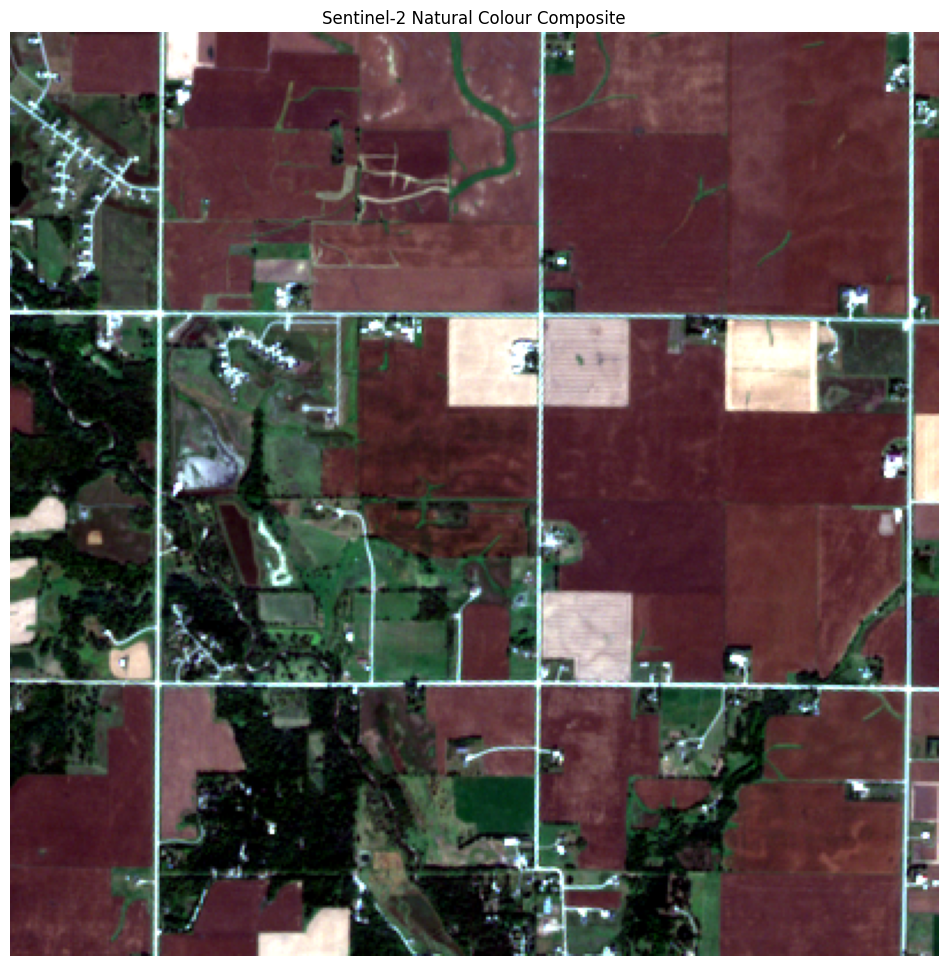

In [37]:
import numpy as np
import matplotlib.pyplot as plt
import rasterio

with rasterio.open(image_path) as src:

    blue = src.read(1).astype("float32")
    green = src.read(2).astype("float32")
    red = src.read(3).astype("float32")

def stretch_band(band, lower=2, upper=98):

    valid = np.isfinite(band) & (band > 0)

    low = np.percentile(band[valid], lower)
    high = np.percentile(band[valid], upper)

    stretched = np.clip(
        (band - low) / (high - low),
        0,
        1
    )

    stretched[~valid] = 0

    return stretched

# Contrast stretching
red_stretched = stretch_band(red)
green_stretched = stretch_band(green)
blue_stretched = stretch_band(blue)

# Natural-colour RGB
rgb = np.dstack((
    red_stretched,
    green_stretched,
    blue_stretched
))

# Visualization
plt.figure(figsize=(14, 12))
plt.imshow(rgb)
plt.title("Sentinel-2 Natural Colour Composite")
plt.axis("off")
plt.show()

In [38]:
### Integrate the model with the processed image

In [39]:
from pathlib import Path
import subprocess
import math

PROJECT_DIR = Path("/content/Boundary_detection_FTW")

# Your already processed Sentinel-2 image
IMAGE_PATH = Path(
    "/content/Boundary_detection_FTW/satellite_preprocessing/S2B_MSIL2A_20250927T165959_R069_T15TVG_20250927T224244_preprocessed.tif"
)

# FTW output directory
OUTPUT_DIR = Path("/content/Boundary_detection_FTW/gps_ftw_output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project exists:", PROJECT_DIR.exists())
print("Processed image exists:", IMAGE_PATH.exists())
print("Output directory:", OUTPUT_DIR)

Project exists: True
Processed image exists: True
Output directory: /content/Boundary_detection_FTW/gps_ftw_output


In [49]:
from pathlib import Path
import rasterio

SATELLITE_DIR = Path(
    "/content/Boundary_detection_FTW/satellite_preprocessing"
)

for file in SATELLITE_DIR.glob("*_preprocessed.tif"):
    with rasterio.open(file) as src:
        print("\nImage:", file.name)
        print("Date:", file.name.split("_")[2][:8])
        print("Bands:", src.count)
        print("Dimensions:", src.width, "x", src.height)
        print("CRS:", src.crs)


Image: S2B_MSIL2A_20250927T165959_R069_T15TVG_20250927T224244_preprocessed.tif
Date: 20250927
Bands: 4
Dimensions: 404 x 402
CRS: EPSG:32615

Image: S2B_MSIL2A_20251010T171139_R112_T15TVG_20251010T220405_preprocessed.tif
Date: 20251010
Bands: 4
Dimensions: 404 x 402
CRS: EPSG:32615


In [59]:
import rasterio
import numpy as np

# Read the two processed images
with rasterio.open(IMAGE_1) as src1, rasterio.open(IMAGE_2) as src2:

    image_1 = src1.read()
    image_2 = src2.read()

    profile = src1.profile.copy()

    # Original order: B02, B03, B04, B08
    # Required order: B04, B03, B02, B08

    image_1_corrected = image_1[[2, 1, 0, 3]]
    image_2_corrected = image_2[[2, 1, 0, 3]]

    # Combine both dates
    corrected_stack = np.concatenate(
        [image_1_corrected, image_2_corrected],
        axis=0
    )

    profile.update(
        count=8,
        dtype="uint16",
        compress="deflate"
    )

    CORRECTED_STACK = SATELLITE_DIR / "FTW_two_date_stack_corrected.tif"

    with rasterio.open(CORRECTED_STACK, "w", **profile) as dst:

        dst.write(corrected_stack)

        descriptions = [
            "September_B04",
            "September_B03",
            "September_B02",
            "September_B08",
            "October_B04",
            "October_B03",
            "October_B02",
            "October_B08"
        ]

        for i, name in enumerate(descriptions, start=1):
            dst.set_band_description(i, name)

print("Corrected stack created:", CORRECTED_STACK)
print("Shape:", corrected_stack.shape)

Corrected stack created: /content/Boundary_detection_FTW/satellite_preprocessing/FTW_two_date_stack_corrected.tif
Shape: (8, 402, 404)


In [60]:
import subprocess

CORRECTED_STACK = SATELLITE_DIR / "FTW_two_date_stack_corrected.tif"
CORRECTED_INFERENCE = SATELLITE_DIR / "FTW_two_date_stack_corrected_inference.tif"

cmd = [
    "/usr/local/bin/ftw", "inference", "run",
    str(CORRECTED_STACK),
    "--model", "FTW_PRUE_EFNET_B5_CCBY",
    "--out", str(CORRECTED_INFERENCE),
    "--gpu", "0",
    "--overwrite"
]

result = subprocess.run(cmd, capture_output=True, text=True)

print("Return code:", result.returncode)
print(result.stdout)
if result.stderr:
    print(result.stderr)

Return code: 0
Input image size: 402x404 pixels (HxW)
Patch size: 256
Padding: 16
Finished inference and saved output to /content/Boundary_detection_FTW/satellite_preprocessing/FTW_two_date_stack_corrected_inference.tif in 2.03s

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()

  0%|          | 0/2 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.

In [61]:
import rasterio
import numpy as np

with rasterio.open(CORRECTED_INFERENCE) as src:
    prediction = src.read(1)

values, counts = np.unique(prediction, return_counts=True)

print("Prediction shape:", prediction.shape)
print("\nPixel class counts:")

for value, count in zip(values, counts):
    print(f"Class {value}: {count:,} pixels")

print("\nTotal pixels:", prediction.size)

Prediction shape: (402, 404)

Pixel class counts:
Class 0: 59,492 pixels
Class 1: 92,694 pixels
Class 2: 10,222 pixels

Total pixels: 162408


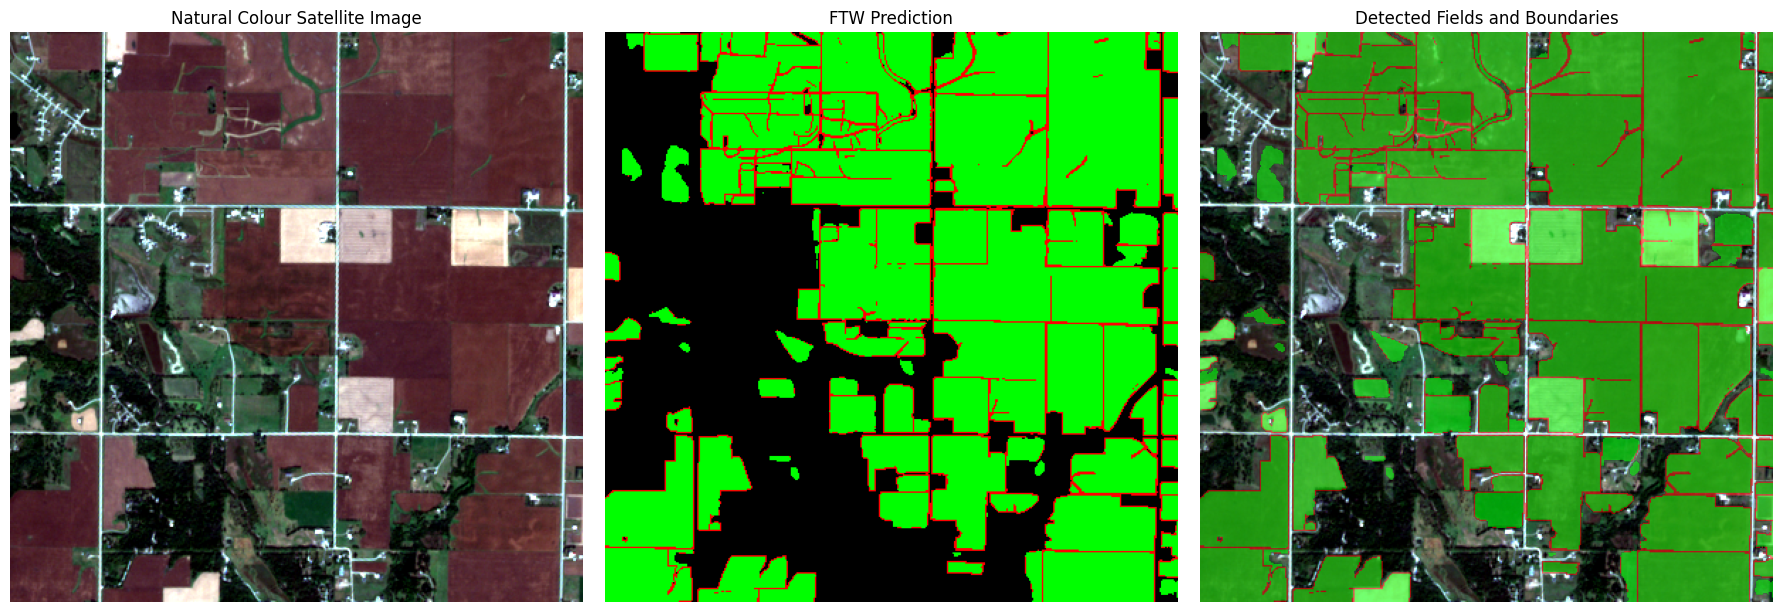

In [62]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm

# Read the September image
with rasterio.open(IMAGE_1) as src:
    image = src.read()

# Original band order: B02, B03, B04, B08
# Natural colour order: Red, Green, Blue
rgb = np.stack(
    [image[2], image[1], image[0]],
    axis=-1
).astype(float)

# Contrast enhancement for display
for band in range(3):
    valid = rgb[:, :, band] > 0
    if np.any(valid):
        low, high = np.percentile(rgb[:, :, band][valid], [2, 98])
        rgb[:, :, band] = np.clip(
            (rgb[:, :, band] - low) / (high - low + 1e-6),
            0, 1
        )

# Read corrected prediction
with rasterio.open(CORRECTED_INFERENCE) as src:
    prediction = src.read(1)

# Hide background class (0) in the overlay
overlay = np.ma.masked_where(prediction == 0, prediction)

cmap = ListedColormap(["lime", "red"])
norm = BoundaryNorm([0.5, 1.5, 2.5], cmap.N)

# Display
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(rgb)
axes[0].set_title("Natural Colour Satellite Image")

axes[1].imshow(prediction, cmap=ListedColormap(
    ["black", "lime", "red"]
), vmin=0, vmax=2)
axes[1].set_title("FTW Prediction")

axes[2].imshow(rgb)
axes[2].imshow(overlay, cmap=cmap, norm=norm, alpha=0.55)
axes[2].set_title("Detected Fields and Boundaries")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [63]:
import subprocess

POLYGON_FILE = SATELLITE_DIR / "FTW_two_date_stack_corrected_polygons.parquet"

cmd = [
    "/usr/local/bin/ftw", "inference", "polygonize",
    str(CORRECTED_INFERENCE),
    "--out", str(POLYGON_FILE),
    "--simplify", "0",
    "--min_size", "0",
    "--overwrite"
]

result = subprocess.run(cmd, capture_output=True, text=True)

print("Return code:", result.returncode)
print(result.stdout)

if result.stderr:
    print(result.stderr)

Return code: 0
Polygonizing input file: /content/Boundary_detection_FTW/satellite_preprocessing/FTW_two_date_stack_corrected_inference.tif
Finished polygonizing output at /content/Boundary_detection_FTW/satellite_preprocessing/FTW_two_date_stack_corrected_polygons.parquet in 1.55s


Processing mask windows: 100%|██████████| 1/1 [00:00<00:00,  7.94it/s]



In [70]:

import geopandas as gpd
import pandas as pd
import numpy as np

# Read FTW polygon output
gdf = gpd.read_parquet(POLYGON_FILE)

print("Total polygons detected:", len(gdf))
print("Original CRS:", gdf.crs)

# Convert to projected CRS for measurements in metres
gdf = gdf.to_crs("EPSG:32615")

# Calculate area
gdf["area_sqm"] = gdf.geometry.area
gdf["area_hectares"] = gdf["area_sqm"] / 10000
gdf["area_acres"] = gdf["area_sqm"] / 4046.8564224

# Calculate perimeter
gdf["perimeter_m"] = gdf.geometry.length

# Calculate bounding box dimensions
bounds = gdf.geometry.bounds
gdf["bbox_width_m"] = bounds["maxx"] - bounds["minx"]
gdf["bbox_height_m"] = bounds["maxy"] - bounds["miny"]

# Calculate compactness
gdf["compactness"] = (
    4 * np.pi * gdf["area_sqm"] /
    (gdf["perimeter_m"] ** 2)
)

# Calculate centroid coordinates
centroids = gdf.geometry.centroid

centroids_wgs84 = gpd.GeoSeries(
    centroids, crs=gdf.crs
).to_crs("EPSG:4326")

gdf["centroid_longitude"] = centroids_wgs84.x
gdf["centroid_latitude"] = centroids_wgs84.y

# Create output DataFrame
result = pd.DataFrame({
    "polygon_id": range(1, len(gdf) + 1),
    "area_sqm": gdf["area_sqm"].values,
    "area_hectares": gdf["area_hectares"].values,
    "area_acres": gdf["area_acres"].values,
    "perimeter_m": gdf["perimeter_m"].values,
    "bbox_width_m": gdf["bbox_width_m"].values,
    "bbox_height_m": gdf["bbox_height_m"].values,
    "compactness": gdf["compactness"].values,
    "centroid_latitude": gdf["centroid_latitude"].values,
    "centroid_longitude": gdf["centroid_longitude"].values,

    # Shortened geometry display
    "geometry": (
        gdf.geometry.to_wkt().str.slice(0, 60) + "..."
    )
})

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 50)
pd.set_option("display.width", None)

display(result.round(4))


Total polygons detected: 118
Original CRS: {"$schema": "https://proj.org/schemas/v0.7/projjson.schema.json", "type": "ProjectedCRS", "name": "WGS 84 / UTM zone 15N", "base_crs": {"type": "GeographicCRS", "name": "WGS 84", "datum_ensemble": {"name": "World Geodetic System 1984 ensemble", "members": [{"name": "World Geodetic System 1984 (Transit)"}, {"name": "World Geodetic System 1984 (G730)"}, {"name": "World Geodetic System 1984 (G873)"}, {"name": "World Geodetic System 1984 (G1150)"}, {"name": "World Geodetic System 1984 (G1674)"}, {"name": "World Geodetic System 1984 (G1762)"}, {"name": "World Geodetic System 1984 (G2139)"}, {"name": "World Geodetic System 1984 (G2296)"}], "ellipsoid": {"name": "WGS 84", "semi_major_axis": 6378137, "inverse_flattening": 298.257223563}, "accuracy": "2.0", "id": {"authority": "EPSG", "code": 6326}}, "coordinate_system": {"subtype": "ellipsoidal", "axis": [{"name": "Geodetic latitude", "abbreviation": "Lat", "direction": "north", "unit": "degree"}, {"n

,polygon_id,area_sqm,area_hectares,area_acres,perimeter_m,bbox_width_m,bbox_height_m,compactness,centroid_latitude,centroid_longitude,geometry
0,1,2100.0,0.21,0.5189,440.0,210.0,10.0,0.1363,42.1179,-93.7016,"POLYGON ((441900 4663110, 441900 4663100, 4421..."
1,2,5800.0,0.58,1.4332,460.0,140.0,90.0,0.3444,42.1178,-93.6889,"POLYGON ((442960 4663110, 442960 4663100, 4429..."
2,3,10700.0,1.07,2.6440,480.0,120.0,110.0,0.5836,42.1174,-93.7042,"POLYGON ((441730 4663100, 441730 4663060, 4417..."
3,4,8600.0,0.86,2.1251,500.0,80.0,120.0,0.4323,42.1176,-93.6599,"POLYGON ((445420 4663110, 445420 4663090, 4454..."
4,5,2000.0,0.20,0.4942,240.0,80.0,40.0,0.4363,42.1166,-93.6774,"POLYGON ((444010 4662970, 444010 4662960, 4439..."
...,...,...,...,...,...,...,...,...,...,...,...
113,114,201200.0,20.12,49.7176,2540.0,610.0,380.0,0.3919,42.0833,-93.7030,"POLYGON ((441580 4659470, 441580 4659090, 4421..."
114,115,273400.0,27.34,67.5586,2280.0,780.0,360.0,0.6609,42.0835,-93.6643,"POLYGON ((444680 4659450, 444680 4659440, 4446..."
115,116,53100.0,5.31,13.1213,1200.0,400.0,200.0,0.4634,42.0825,-93.6903,"POLYGON ((442930 4659290, 442930 4659280, 4429..."
116,117,127800.0,12.78,31.5801,2560.0,620.0,320.0,0.2451,42.0832,-93.6943,"POLYGON ((442470 4659410, 442470 4659400, 4424..."


Total detected polygons: 118
Polygon CRS: {"$schema": "https://proj.org/schemas/v0.7/projjson.schema.json", "type": "ProjectedCRS", "name": "WGS 84 / UTM zone 15N", "base_crs": {"type": "GeographicCRS", "name": "WGS 84", "datum_ensemble": {"name": "World Geodetic System 1984 ensemble", "members": [{"name": "World Geodetic System 1984 (Transit)"}, {"name": "World Geodetic System 1984 (G730)"}, {"name": "World Geodetic System 1984 (G873)"}, {"name": "World Geodetic System 1984 (G1150)"}, {"name": "World Geodetic System 1984 (G1674)"}, {"name": "World Geodetic System 1984 (G1762)"}, {"name": "World Geodetic System 1984 (G2139)"}, {"name": "World Geodetic System 1984 (G2296)"}], "ellipsoid": {"name": "WGS 84", "semi_major_axis": 6378137, "inverse_flattening": 298.257223563}, "accuracy": "2.0", "id": {"authority": "EPSG", "code": 6326}}, "coordinate_system": {"subtype": "ellipsoidal", "axis": [{"name": "Geodetic latitude", "abbreviation": "Lat", "direction": "north", "unit": "degree"}, {"na

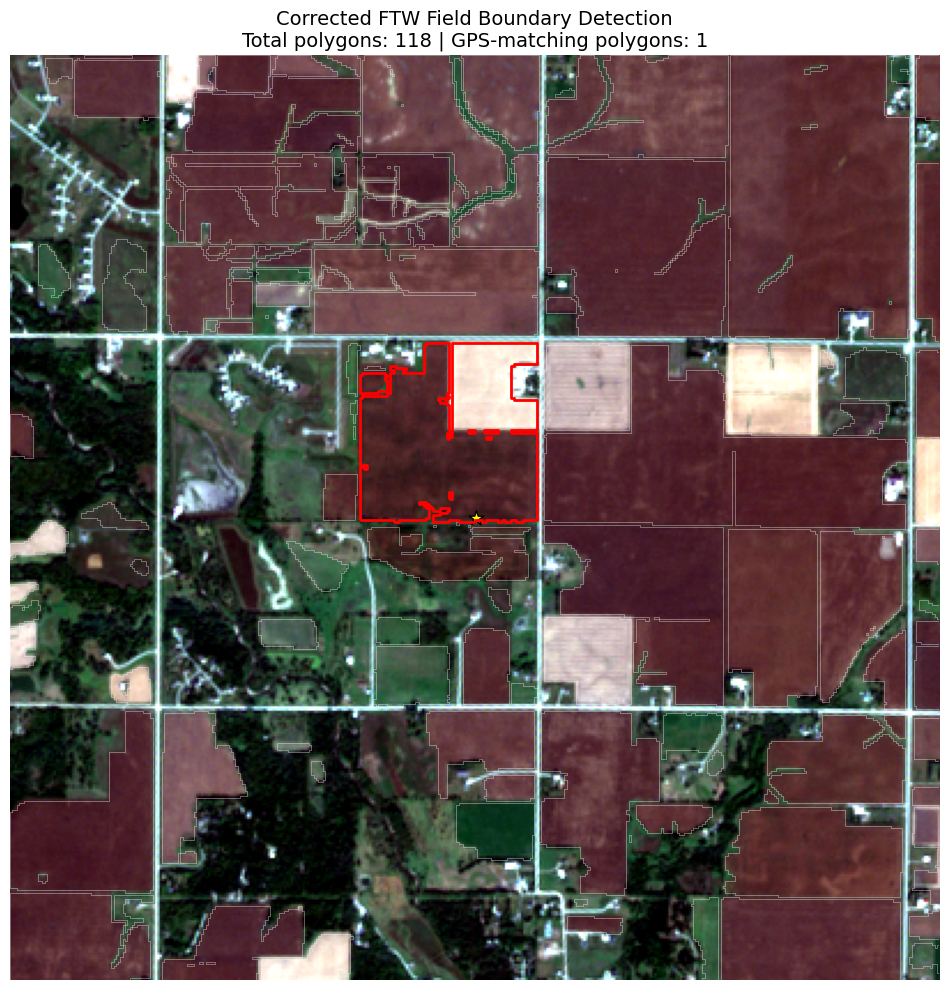


Selected Polygon Details:


,area_hectares,perimeter_m,geometry
56,52.89,6080.0,"POLYGON ((443390 4661860, 443390 4661850, 4433..."


In [86]:

import geopandas as gpd
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import Point
from rasterio.transform import array_bounds

# --------------------------------------------------
# 1. Load corrected FTW polygon output
# --------------------------------------------------

gdf = gpd.read_parquet(POLYGON_FILE)

print("Total detected polygons:", len(gdf))
print("Polygon CRS:", gdf.crs)

if gdf.crs is None:
    raise ValueError("Polygon CRS is missing.")

# --------------------------------------------------
# 2. Load September satellite image
# --------------------------------------------------

with rasterio.open(IMAGE_1) as src:

    # Original band order: B02, B03, B04, B08
    image = src.read()

    # Natural RGB order: B04, B03, B02
    rgb = np.stack(
        [image[2], image[1], image[0]],
        axis=-1
    ).astype(float)

    out_transform = src.transform
    image_crs = src.crs

# Apply contrast enhancement
for band in range(3):

    valid = rgb[:, :, band] > 0

    if np.any(valid):
        low, high = np.percentile(
            rgb[:, :, band][valid], [2, 98]
        )

        rgb[:, :, band] = np.clip(
            (rgb[:, :, band] - low) /
            (high - low + 1e-6),
            0, 1
        )

# --------------------------------------------------
# 3. GPS coordinates
# --------------------------------------------------

latitude = 42.099946
longitude = -93.681996

gps_point = gpd.GeoDataFrame(
    geometry=[Point(longitude, latitude)],
    crs="EPSG:4326"
)

# Convert GPS point to polygon CRS
gps_point = gps_point.to_crs(gdf.crs)

# --------------------------------------------------
# 4. Find GPS-matching polygon
# --------------------------------------------------

gps_geometry = gps_point.geometry.iloc[0]

matches = gdf[
    gdf.geometry.apply(
        lambda geom: geom.covers(gps_geometry)
    )
].copy()

print("GPS-matching polygons:", len(matches))

# --------------------------------------------------
# 5. Plot satellite image and selected polygon
# --------------------------------------------------

if len(matches) > 0:

    height, width = rgb.shape[:2]

    left, bottom, right, top = array_bounds(
        height, width, out_transform
    )

    # Convert polygons and GPS point to image CRS
    gdf_sat = gdf.to_crs(image_crs)
    matches_sat = matches.to_crs(image_crs)
    gps_sat = gps_point.to_crs(image_crs)

    fig, ax = plt.subplots(figsize=(12, 10))

    # Natural-colour satellite image
    ax.imshow(
        rgb,
        extent=[left, right, bottom, top],
        origin="upper"
    )

    # All detected farmland polygon boundaries
    # Draw all detected polygon boundaries
    gdf_sat.boundary.plot(
    ax=ax,
    edgecolor="white",
    linewidth=0.5,
    alpha=0.5,
    zorder=2
)

# Draw selected polygon boundary on top
    matches_sat.boundary.plot(
    ax=ax,
    edgecolor="red",
    linewidth=2,
    linestyle="-",
    zorder=5
)

    # GPS location
    gps_sat.plot(
        ax=ax,
        color="yellow",
        markersize=120,
        marker="*",
        edgecolor="black"
    )

    # Plot title
    ax.set_title(
        f"Corrected FTW Field Boundary Detection\n"
        f"Total polygons: {len(gdf)} | "
        f"GPS-matching polygons: {len(matches)}",
        fontsize=14
    )

    ax.set_xlim(left, right)
    ax.set_ylim(bottom, top)
    ax.set_axis_off()

    plt.tight_layout()
    plt.show()

    # --------------------------------------------------
    # 6. Display selected polygon measurements
    # --------------------------------------------------

    print("\nSelected Polygon Details:")

    selected_details = matches.copy()

    selected_details["area_hectares"] = (
        selected_details.geometry.area / 10000
    )

    selected_details["perimeter_m"] = (
        selected_details.geometry.length
    )

    display(
        selected_details[
            ["area_hectares", "perimeter_m", "geometry"]
        ].round(3)
    )

else:
    print("No matching polygon found for this GPS location.")


In [85]:

import rasterio
import numpy as np
import geopandas as gpd

from shapely.geometry import Point, mapping
from rasterio.features import geometry_mask

# --------------------------------------------------
# 1. Load September Sentinel-2 image
# --------------------------------------------------

with rasterio.open(IMAGE_1) as src:

    # Band order: B02, B03, B04, B08
    # B04 = Red (Band 3)
    # B08 = NIR (Band 4)

    red = src.read(3, masked=True).astype("float32")
    nir = src.read(4, masked=True).astype("float32")

    image_crs = src.crs
    image_transform = src.transform
    image_height = src.height
    image_width = src.width

print("Image CRS:", image_crs)
print("Image dimensions:", image_height, "x", image_width)

# --------------------------------------------------
# 2. Convert masked arrays
# --------------------------------------------------

red_array = np.ma.filled(red, np.nan).astype("float32")
nir_array = np.ma.filled(nir, np.nan).astype("float32")

# --------------------------------------------------
# 3. Calculate NDVI
# --------------------------------------------------

denominator = nir_array + red_array

valid = (
    np.isfinite(red_array)
    & np.isfinite(nir_array)
    & (red_array > 0)
    & (nir_array > 0)
    & (denominator > 0)
)

ndvi = np.full(
    red_array.shape,
    np.nan,
    dtype="float32"
)

ndvi[valid] = (
    (nir_array[valid] - red_array[valid])
    / denominator[valid]
)

print("\n===== NDVI CALCULATION COMPLETE =====")
print("Total pixels:", ndvi.size)
print("Valid pixels:", np.count_nonzero(np.isfinite(ndvi)))

# --------------------------------------------------
# 4. Save NDVI raster
# --------------------------------------------------

NDVI_OUTPUT = SATELLITE_DIR / "September_2025_NDVI.tif"

with rasterio.open(IMAGE_1) as src:

    profile = src.profile.copy()

    profile.update(
        count=1,
        dtype="float32",
        nodata=-9999.0,
        compress="deflate"
    )

    ndvi_to_save = np.where(
        np.isfinite(ndvi),
        ndvi,
        -9999.0
    ).astype("float32")

    with rasterio.open(
        NDVI_OUTPUT,
        "w",
        **profile
    ) as dst:

        dst.write(ndvi_to_save, 1)

print("NDVI raster saved:", NDVI_OUTPUT)

# --------------------------------------------------
# 5. Load corrected FTW polygons
# --------------------------------------------------

gdf = gpd.read_parquet(POLYGON_FILE)

# --------------------------------------------------
# 6. Identify GPS-selected polygon
# --------------------------------------------------

latitude = 42.099946
longitude = -93.681996

gps_point = gpd.GeoDataFrame(
    geometry=[Point(longitude, latitude)],
    crs="EPSG:4326"
)

gps_point = gps_point.to_crs(gdf.crs)

gps_geometry = gps_point.geometry.iloc[0]

matches = gdf[
    gdf.geometry.apply(
        lambda geom: geom.covers(gps_geometry)
    )
].copy()

print("\nGPS-matching polygons:", len(matches))

# --------------------------------------------------
# 7. Calculate NDVI statistics for selected polygon
# --------------------------------------------------

if len(matches) > 0:

    matches_sat = matches.to_crs(image_crs)

    selected_geometries = [
        mapping(geom)
        for geom in matches_sat.geometry
    ]

    polygon_mask = geometry_mask(
        selected_geometries,
        out_shape=(image_height, image_width),
        transform=image_transform,
        invert=True,
        all_touched=False
    )

    selected_valid = (
        polygon_mask
        & np.isfinite(ndvi)
    )

    selected_ndvi = ndvi[selected_valid]

    print("\n===== SELECTED FIELD NDVI STATISTICS =====")

    if len(selected_ndvi) > 0:

        mean_ndvi = np.mean(selected_ndvi)
        median_ndvi = np.median(selected_ndvi)
        min_ndvi = np.min(selected_ndvi)
        max_ndvi = np.max(selected_ndvi)
        std_ndvi = np.std(selected_ndvi)

        # Vegetation threshold
        vegetation_pixels = np.count_nonzero(
            selected_ndvi > 0.30
        )

        low_vegetation_pixels = np.count_nonzero(
            selected_ndvi <= 0.30
        )

        vegetation_percentage = (
            vegetation_pixels / len(selected_ndvi)
        ) * 100

        low_vegetation_percentage = (
            low_vegetation_pixels / len(selected_ndvi)
        ) * 100

        print("Valid polygon pixels:", len(selected_ndvi))
        print(f"Mean NDVI: {mean_ndvi:.3f}")
        print(f"Median NDVI: {median_ndvi:.3f}")
        print(f"Minimum NDVI: {min_ndvi:.3f}")
        print(f"Maximum NDVI: {max_ndvi:.3f}")
        print(f"Standard deviation: {std_ndvi:.3f}")

        print("\n===== VEGETATION COVERAGE =====")

        print(
            f"Pixels with NDVI > 0.30: "
            f"{vegetation_percentage:.2f}%"
        )

        print(
            f"Pixels with NDVI <= 0.30: "
            f"{low_vegetation_percentage:.2f}%"
        )

    else:
        print("No valid NDVI pixels inside the selected polygon.")

else:
    print("No GPS-matching polygon found.")


Image CRS: EPSG:32615
Image dimensions: 402 x 404

===== NDVI CALCULATION COMPLETE =====
Total pixels: 162408
Valid pixels: 162408
NDVI raster saved: /content/Boundary_detection_FTW/satellite_preprocessing/September_2025_NDVI.tif

GPS-matching polygons: 1

===== SELECTED FIELD NDVI STATISTICS =====
Valid polygon pixels: 5289
Mean NDVI: 0.169
Median NDVI: 0.169
Minimum NDVI: 0.084
Maximum NDVI: 0.581
Standard deviation: 0.047

===== VEGETATION COVERAGE =====
Pixels with NDVI > 0.30: 0.85%
Pixels with NDVI <= 0.30: 99.15%


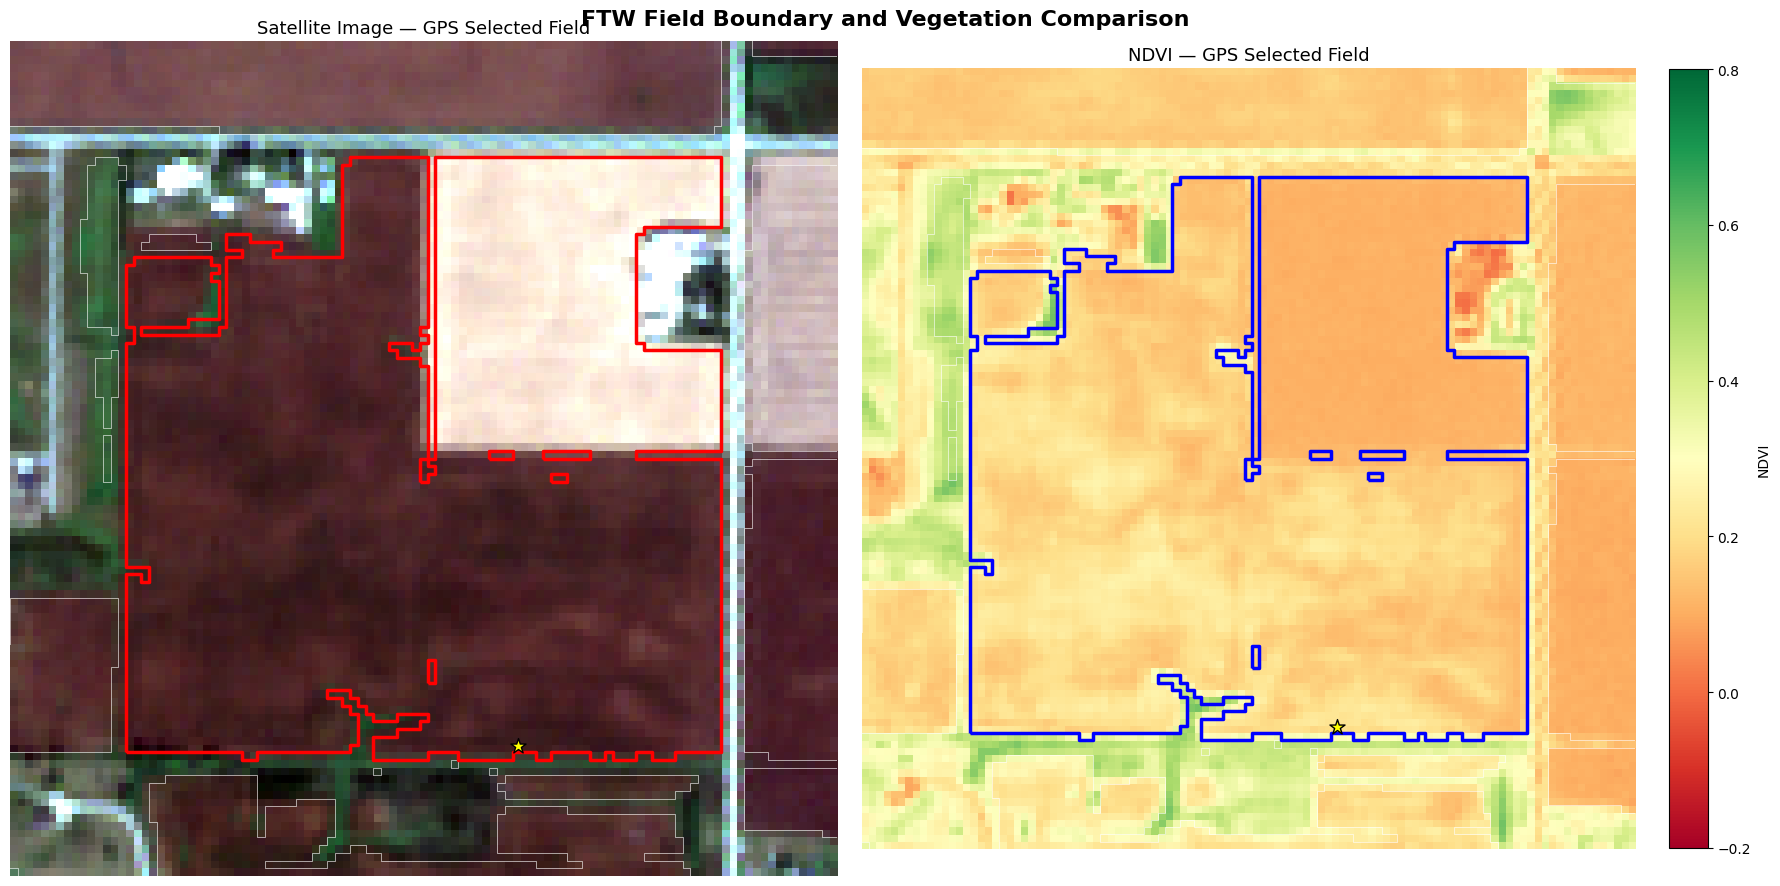

In [84]:

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np

from rasterio.transform import array_bounds
from rasterio.warp import transform_bounds

# --------------------------------------------------
# 1. Validate required variables
# --------------------------------------------------

if len(matches) > 0:

    if "ndvi" not in globals():
        raise ValueError("Run the NDVI calculation cell first.")

    if "rgb" not in globals():
        raise ValueError("Run the satellite RGB image cell first.")

    if "image_transform" not in globals():
        raise ValueError("Image transform is missing. Run the NDVI cell first.")

    if "image_crs" not in globals():
        raise ValueError("Image CRS is missing.")

    # --------------------------------------------------
    # 2. Convert polygons and GPS point to NDVI CRS
    # --------------------------------------------------

    gdf_ndvi = gdf.to_crs(image_crs)
    matches_ndvi = matches.to_crs(image_crs)
    gps_ndvi = gps_point.to_crs(image_crs)

    # Select GPS-matching field
    field = matches_ndvi.geometry.iloc[0]

    # --------------------------------------------------
    # 3. Zoom around selected field
    # --------------------------------------------------

    minx, miny, maxx, maxy = field.bounds

    margin = 150  # metres

    xmin = minx - margin
    xmax = maxx + margin
    ymin = miny - margin
    ymax = maxy + margin

    # --------------------------------------------------
    # 4. Calculate satellite RGB image bounds
    # --------------------------------------------------

    rgb_height, rgb_width = rgb.shape[:2]

    rgb_left, rgb_bottom, rgb_right, rgb_top = array_bounds(
        rgb_height,
        rgb_width,
        image_transform
    )

    # --------------------------------------------------
    # 5. Calculate NDVI image bounds
    # --------------------------------------------------

    ndvi_height, ndvi_width = ndvi.shape

    ndvi_left, ndvi_bottom, ndvi_right, ndvi_top = array_bounds(
        ndvi_height,
        ndvi_width,
        image_transform
    )

    # --------------------------------------------------
    # 6. Create side-by-side comparison
    # --------------------------------------------------

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(18, 9)
    )

    # ==================================================
    # LEFT: Natural-colour satellite image
    # ==================================================

    axes[0].imshow(
        rgb,
        extent=[
            rgb_left,
            rgb_right,
            rgb_bottom,
            rgb_top
        ],
        origin="upper"
    )

    # All FTW detected field boundaries
    gdf_ndvi.boundary.plot(
        ax=axes[0],
        edgecolor="white",
        linewidth=0.6,
        alpha=0.7
    )

    # GPS-selected field boundary
    matches_ndvi.boundary.plot(
        ax=axes[0],
        edgecolor="red",
        linewidth=2.5,
        linestyle="-",
        zorder=5
    )

    # GPS location
    gps_ndvi.plot(
        ax=axes[0],
        color="yellow",
        marker="*",
        markersize=130,
        edgecolor="black",
        zorder=6
    )

    axes[0].set_xlim(xmin, xmax)
    axes[0].set_ylim(ymin, ymax)

    axes[0].set_title(
        "Satellite Image — GPS Selected Field",
        fontsize=13
    )

    axes[0].set_axis_off()

    # ==================================================
    # RIGHT: NDVI image
    # ==================================================

    im = axes[1].imshow(
        ndvi,
        extent=[
            ndvi_left,
            ndvi_right,
            ndvi_bottom,
            ndvi_top
        ],
        origin="upper",
        cmap="RdYlGn",
        vmin=-0.2,
        vmax=0.8
    )

    # All FTW detected field boundaries
    gdf_ndvi.boundary.plot(
        ax=axes[1],
        edgecolor="white",
        linewidth=0.6,
        alpha=0.7
    )

    # GPS-selected field boundary
    matches_ndvi.boundary.plot(
        ax=axes[1],
        edgecolor="blue",
        linewidth=2.5,
        linestyle="-",
        zorder=5
    )

    # GPS location
    gps_ndvi.plot(
        ax=axes[1],
        color="yellow",
        marker="*",
        markersize=130,
        edgecolor="black",
        zorder=6
    )

    axes[1].set_xlim(xmin, xmax)
    axes[1].set_ylim(ymin, ymax)

    axes[1].set_title(
        "NDVI — GPS Selected Field",
        fontsize=13
    )

    axes[1].set_axis_off()

    # --------------------------------------------------
    # 7. NDVI colour scale
    # --------------------------------------------------

    fig.colorbar(
        im,
        ax=axes[1],
        fraction=0.046,
        pad=0.04,
        label="NDVI"
    )

    # --------------------------------------------------
    # 8. Final layout
    # --------------------------------------------------

    fig.suptitle(
        "FTW Field Boundary and Vegetation Comparison",
        fontsize=16,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()

else:

    print("No farmland polygon matches your GPS location.")
